In [1]:
import sys 
sys.path.append('../src')

from data_processing.load import load_and_preprocess_data

from data_processing.utils import load_checkpoint, save_checkpoint, run_inference_bnn, run_svi
from models.model import model, model_mw_gamma, model_cf_logitnormal, model_cf_beta

import jax
import jax.numpy as jnp
import numpy as np
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from jax import random
import time
from numpyro.infer import MCMC, NUTS, Predictive, SVI, Trace_ELBO
import arviz as az
import scipy
from scipy.stats import percentileofscore
from numpyro.infer.autoguide import AutoNormal, AutoDiagonalNormal
from numpyro.optim import Adam
import numpyro.distributions as dist
from scipy.stats import gaussian_kde
import seaborn as sns
from scipy.stats import gaussian_kde, norm



In [2]:
jax.config.update('jax_num_cpu_devices', 6) # I have 8 physical cores

### Load data and preprocess
- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:
- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)

In [3]:
from operator import itemgetter
data = load_and_preprocess_data()
(X_train, X_test, Y_train_gen, Y_test_gen,
 Y_train_cf, Y_test_cf, Y_train_aval, Y_test_aval,
 sites_meta, feature_cols) = itemgetter(
    "X_train","X_test","Y_train_gen","Y_test_gen",
    "Y_train_cf","Y_test_cf","Y_train_aval","Y_test_aval",
    "sites_meta","feature_cols"
)(data)


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:60: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 6)
Preprocessing done. X_test shape: (2161, 6, 6)


### Simple BNN
input: (timestamps, wind parks, features)
output: (timestamps)


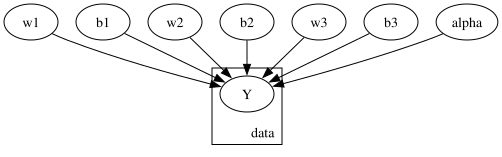

In [4]:
import numpyro
numpyro.render_model(
    model,
    model_args=(X_test,),
)

In [5]:
# args = {
#     'num_warmup': 40,
#     'num_samples': 60,
#     'num_chains': 5,
# }
args = dict(
    num_warmup=50,
    num_samples=100,
    num_chains=1,
)

rng_key, rng_key_predict = random.split(random.PRNGKey(0))

Run MCMC

In [7]:
# simple BNN, but already with Gamma distribution, without softplus, bounded below at 0
# samples = run_inference_bnn(model, args, rng_key, X_train, Y_train_gen)

In [8]:
# preds_MCMC = Predictive(model, samples)(rng_key_predict, X_test)['Y']

In [9]:
# Gamma distribution and softplus, seperate mu and k, bounded below at 0
samples_gamma = run_inference_bnn(model_mw_gamma, args, rng_key, X_train, Y_train_gen)


sample: 100%|██████████| 150/150 [12:57<00:00,  5.19s/it, 1023 steps of size 6.22e-03. acc. prob=0.89]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]      2.06      0.52      2.01      1.13      2.77      4.47      1.07
     b1[1]     -1.84      0.38     -1.80     -2.28     -1.34      4.04      2.08
     b1[2]      0.87      0.28      0.79      0.53      1.40      6.23      1.39
     b1[3]     -0.19      0.16     -0.14     -0.40      0.01      7.03      1.33
     b1[4]     -4.37      0.40     -4.37     -5.00     -3.81     33.81      1.06
     b1[5]      0.11      0.54      0.20     -0.62      0.84      2.85      3.24
     b1[6]     -0.88      0.82     -0.75     -1.85      0.17      3.90      1.73
     b1[7]     -0.52      0.50     -0.22     -1.45     -0.10      3.65      1.63
     b1[8]     -0.15      0.09     -0.16     -0.26      0.01     17.26      1.16
     b1[9]      1.27      0.21      1.30      0.97      1.56     20.39      1.11
    b1[10]      1.98      0.38      1.95      1.27      2.48      6.97      1.01
    b1[11]      1.36      0

In [10]:
samples_gamma.keys()

dict_keys(['alpha', 'b1', 'b2', 'b3k', 'b3mu', 'mu', 'w1', 'w2', 'w3k', 'w3mu'])

In [15]:
state_ckp = load_checkpoint(file_name='model_mw_gamma_2025-11-05_16-27-19_gen') # model_2025-10-21_14-28-15_gen, model_2025-10-23_09-03-57_gen
samples_ckp = state_ckp['samples']
args_ckp = state_ckp['args']
rng_key_ckp = state_ckp['rng_key']
rng_key_ckp, rng_key_predict_ckp = random.split(rng_key_ckp)

Loading specified checkpoint: ../checkpoints/model_mw_gamma_2025-11-05_16-27-19_gen.pkl


In [12]:
predictive = Predictive(model_mw_gamma, samples_gamma)(rng_key_predict, X_test)

preds_MCMC_mw_gamma = predictive['Y']
mu = predictive['mu']
alpha = predictive['alpha']


In [32]:
# Logit Normal, bounded between 0 and 1
samples_logitnormal = run_inference_bnn(model_cf_logitnormal, args, rng_key, X_train, Y_train_cf)

sample: 100%|██████████| 150/150 [14:28<00:00,  5.79s/it, 1023 steps of size 1.04e-03. acc. prob=0.94]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]     -0.26      0.11     -0.28     -0.42     -0.09     13.74      1.15
     b1[1]      0.56      0.10      0.56      0.40      0.73      6.39      1.37
     b1[2]      2.67      0.28      2.72      2.25      3.11      8.50      1.01
     b1[3]     -0.76      0.09     -0.75     -0.89     -0.61     24.96      1.00
     b1[4]      0.42      0.25      0.42     -0.10      0.71      3.86      1.89
     b1[5]     -0.44      0.08     -0.43     -0.60     -0.34      5.16      1.58
     b1[6]      0.98      0.19      1.00      0.73      1.33      3.99      1.46
     b1[7]      2.61      0.31      2.63      2.10      3.01      4.12      1.78
     b1[8]     -0.16      0.29     -0.15     -0.56      0.33      3.73      1.74
     b1[9]      0.46      0.13      0.42      0.25      0.66      3.81      1.73
    b1[10]     -1.52      0.14     -1.49     -1.74     -1.32     11.44      0.99
    b1[11]      0.53      0

In [33]:
preds_MCMC_cf_lgit = jax.nn.sigmoid(Predictive(model_cf_logitnormal, samples_logitnormal)(rng_key_predict, X_test)['y_star'])

In [6]:
# Logit Normal, bounded between 0 and 1
samples_beta = run_inference_bnn(model_cf_beta, args, rng_key, X_train, Y_train_cf)

sample: 100%|██████████| 150/150 [15:45<00:00,  6.30s/it, 1023 steps of size 2.39e-04. acc. prob=0.97]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]      3.08      0.16      3.05      2.80      3.35      7.67      1.04
     b1[1]      4.23      0.44      4.23      3.65      4.90      4.54      1.48
     b1[2]      1.67      0.31      1.60      1.19      2.23      4.37      1.63
     b1[3]      0.48      0.09      0.47      0.34      0.60      4.91      1.55
     b1[4]     -2.22      0.10     -2.24     -2.35     -2.06      8.23      1.15
     b1[5]     -2.05      0.17     -2.07     -2.32     -1.82     13.70      1.04
     b1[6]     -2.13      0.19     -2.16     -2.47     -1.84      4.68      1.50
     b1[7]     -4.38      0.45     -4.49     -4.88     -3.40      6.88      1.15
     b1[8]     -2.99      0.13     -2.98     -3.18     -2.82     19.83      1.02
     b1[9]      1.33      0.15      1.37      1.10      1.56      3.84      1.39
    b1[10]      0.06      0.07      0.06     -0.08      0.15     21.23      1.03
    b1[11]      2.39      0

In [ ]:
predictive_beta = Predictive(model_cf_beta, samples_beta)(rng_key_predict, X_test)
preds_MCMC_cf_beta = predictive_beta['y']
cf_alpha= predictive_beta['alpha']
cf_alpha= predictive_beta['alpha']
cf_beta = predictive_beta['beta']
#cf_mu = predictive_beta['mu']

In [34]:
save_checkpoint(samples_gamma, "model_mw_gamma", args, rng_key, target="gen")

Saved checkpoint for model 'model_mw_gamma': ../checkpoints/model_mw_gamma_2025-11-11_10-43-58_gen.pkl


'../checkpoints/model_mw_gamma_2025-11-11_10-43-58_gen.pkl'

In [35]:
save_checkpoint(samples_logitnormal, "model_cf_logitnormal", args, rng_key, target="cf")

Saved checkpoint for model 'model_cf_logitnormal': ../checkpoints/model_cf_logitnormal_2025-11-11_10-43-58_cf.pkl


'../checkpoints/model_cf_logitnormal_2025-11-11_10-43-58_cf.pkl'

Load checkpoint (MCMC)

In [16]:
preds_MCMC_ckp = Predictive(model_mw_gamma, samples_ckp)(rng_key_predict_ckp, X_test)['Y']

In [19]:
preds_MCMC_ckp

Array([[ 63.384766 , 121.72568  , 121.439835 , ...,  79.7237   ,
        205.52165  , 102.50232  ],
       [216.88106  , 163.04439  , 139.99934  , ..., 123.57914  ,
         73.06542  ,  75.61488  ],
       [ 92.75566  , 206.19148  , 240.04741  , ...,  59.01124  ,
        107.533676 , 133.35446  ],
       ...,
       [221.91092  , 180.59688  , 149.42487  , ..., 229.10933  ,
        104.64591  ,  11.750856 ],
       [176.35583  , 130.5117   , 160.14433  , ...,  12.799054 ,
          7.7076077,  33.270847 ],
       [164.10876  , 131.85     , 147.82288  , ...,  42.529865 ,
         23.475847 , 246.63065  ]], dtype=float32)

Run VI

In [45]:
guide = AutoDiagonalNormal(model_cf_logitnormal)
svi_result = run_svi(model_cf_logitnormal, guide, rng_key, X_train, Y_train_cf, num_steps=5000, lr=1e-4)
params = svi_result.params
preds_VI = jax.nn.sigmoid(Predictive(model_cf_logitnormal, guide=guide, params=params, num_samples=500)(rng_key_predict, X_test)['y_star'])


Final ELBO loss: 3308700416.000


### Evaluation

In [8]:
preds = preds_MCMC_cf_beta
# CF: preds_MCMC and preds_VI
# Gen: preds_MCMC_ckp


In [9]:
preds_mean = preds.mean(axis=0)

# Percentiles, no assumption about shape of distribution, central 95% interval
# 95% of samples fall here
percentiles = np.percentile(preds, [2.5, 97.5], axis=0)
median = np.percentile(preds, 50, axis=0)

# Assumes posterior is Normal, symmetric around mean,
# If it's normal, 95% if samples fall here
preds_std = preds.std(axis=0)
normal_lower = preds_mean - 1.96 * preds_std
normal_upper = preds_mean + 1.96 * preds_std

# HDI (high densitiy interval), narrowest possible interval 
# Most probable 95% region
hdi = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)

# Widths of different intervals (90% CI)
hdi_avg_width = (hdi[:,1]-hdi[:,0]).mean()
percentile_avg_width = (percentiles[1]-percentiles[0]).mean()
normal_ci_avg_width = (normal_upper - normal_lower).mean()

print(f"Percentile width: {percentile_avg_width}")
print(f"HDI width: {hdi_avg_width}")
print(f"Normal width: {normal_ci_avg_width}")


Percentile width: 0.4735342490684819
HDI width: 0.4612532668155064
Normal width: 0.5098422765731812


In [10]:

inside = (Y_test_gen >= percentiles[0]) & (Y_test_gen <= percentiles[1])
coverage_90 = inside.mean()
print(f"\nEmpirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (Y_test_gen <= median).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")



Empirical coverage (0.025–0.975): 0.002
Below median (should be ~0.5): 0.000


In [10]:
rmse = jnp.sqrt(jnp.mean((preds_mean - Y_test_gen) ** 2))
print("Test RMSE (gen prediction):", rmse)

Test RMSE (gen prediction): 199.97417


In [11]:
inside = (Y_test_cf >= percentiles[0]) & (Y_test_cf <= percentiles[1])
coverage_90 = inside.mean()
print(f"\nEmpirical coverage cf (0.025–0.975): {coverage_90:.3f}")

below_median = (Y_test_cf <= median).mean()
print(f"Below median cf (should be ~0.5): {below_median:.3f}")


Empirical coverage cf (0.025–0.975): 0.898
Below median cf (should be ~0.5): 0.388


In [12]:
rmse = jnp.sqrt(jnp.mean((preds_mean * Y_test_aval - Y_test_gen) ** 2))
print("Test RMSE (cf prediction):", rmse)

Test RMSE (cf prediction): 65.927536


Empirical coverage of percentiles

### Plots

Variational Inference loss

Final ELBO loss: 3308700416.000


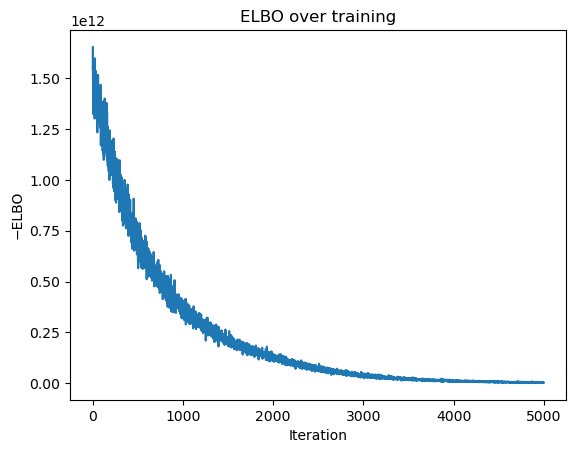

In [54]:
losses = svi_result.losses
print(f"Final ELBO loss: {losses[-1]:.3f}")
plt.plot(losses)
plt.title("ELBO over training")
plt.xlabel("Iteration")
plt.ylabel("−ELBO")
plt.show()


Residuals on training dataset

skew: 0.76636845


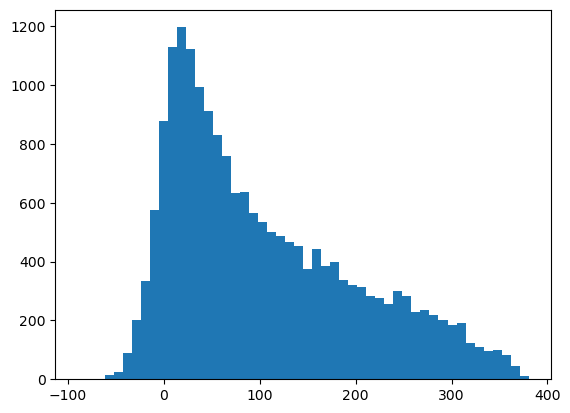

In [17]:
# positive residuals correspond to missed peaks
# positive tail: in general more underpredictions (train data)
pred_train_mcmc = Predictive(model, samples_gamma)(rng_key_predict, X_train)['Y']
#pred_train_vi = Predictive(model, guide=guide, params=params, num_samples=500)(rng_key_predict, X_train)['Y']


pred_train = pred_train_mcmc # or pred_train_mcmc

yhat = jnp.mean(pred_train, axis=0)
resid = Y_train_gen - yhat
print("skew:", scipy.stats.skew(np.array(resid)))
plt.hist(np.array(resid), bins=50); plt.show()

Different intervals (percentile vs. hdi vs. normal)

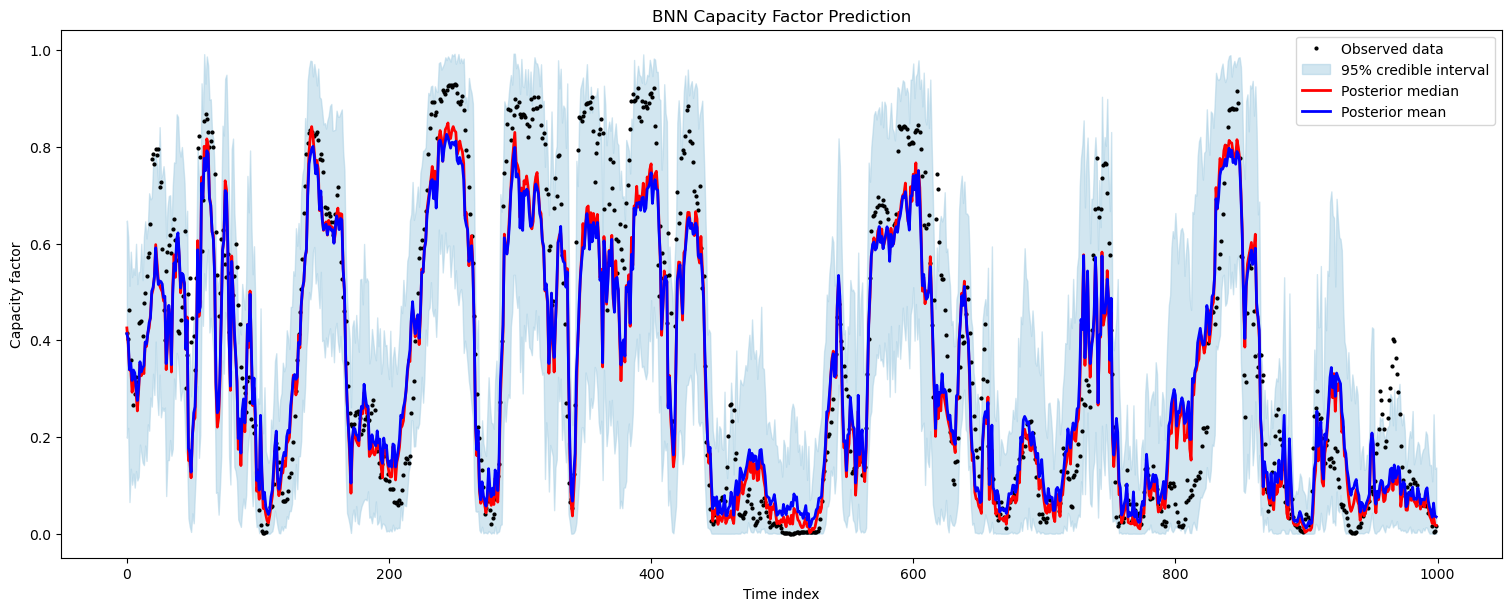

In [13]:
n_plot = 1000
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)

ax.plot(Y_test_cf[:n_plot], ".", color="black", label="Observed data", markersize=4)
ax.fill_between(
    np.arange(n_plot),
    hdi[:n_plot, 0],
    hdi[:n_plot, 1],
    color="#A6CEE3",  # alternative: "#lightgray"
    alpha=0.5,
    label="95% credible interval"
)

ax.plot(median[:n_plot], color="red", label="Posterior median", lw=2)
ax.plot(preds_mean[:n_plot], color="blue", label="Posterior mean", lw=2)

ax.set(
    xlabel="Time index",
    ylabel="Capacity factor",
    title="BNN Capacity Factor Prediction"
)

ax.legend()
plt.show()


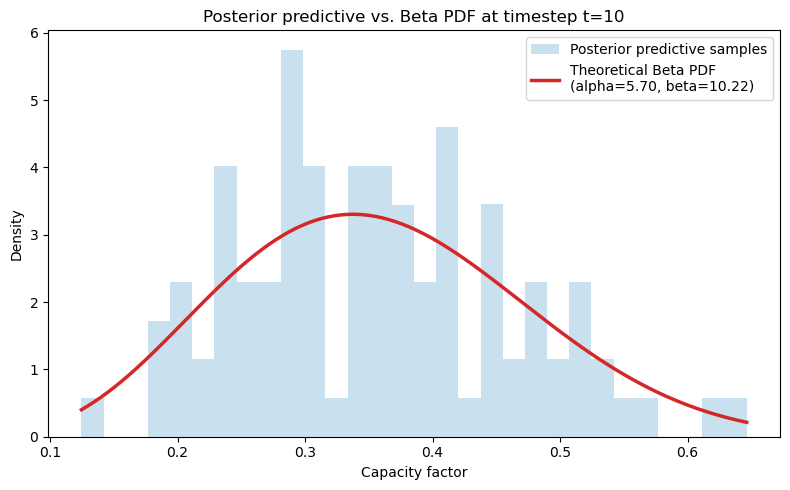

In [18]:
# pick a timestep
t = 10  # or any index you want to inspect

# posterior predictive samples
y_samples = np.array(preds[:, t])
alpha_t_samples = np.array(cf_alpha[:, t])
beta_t_samples = np.array(cf_beta[:, t])

# posterior mean parameters
alpha_t = np.mean(alpha_t_samples)
beta_t = np.mean(beta_t_samples)

# theoretical Beta distribution
beta_dist = dist.Beta(alpha_t, beta_t)
x = np.linspace(y_samples.min(), y_samples.max(), 200)
pdf = np.array(jnp.exp(beta_dist.log_prob(jnp.array(x))))

plt.figure(figsize=(8, 5))
plt.hist(
    y_samples,
    bins=30,
    density=True,
    alpha=0.6,
    color="#A6CEE3",  # soft blue for posterior samples
    label="Posterior predictive samples"
)
plt.plot(
    x, pdf,
    color="#D62728",  # red for theoretical curve
    lw=2.5,
    label=f"Theoretical Beta PDF\n(alpha={alpha_t:.2f}, beta={beta_t:.2f})"
)

plt.xlabel("Capacity factor")
plt.ylabel("Density")
plt.title(f"Posterior predictive vs. Beta PDF at timestep t={t}")
plt.legend()
plt.tight_layout()
plt.show()


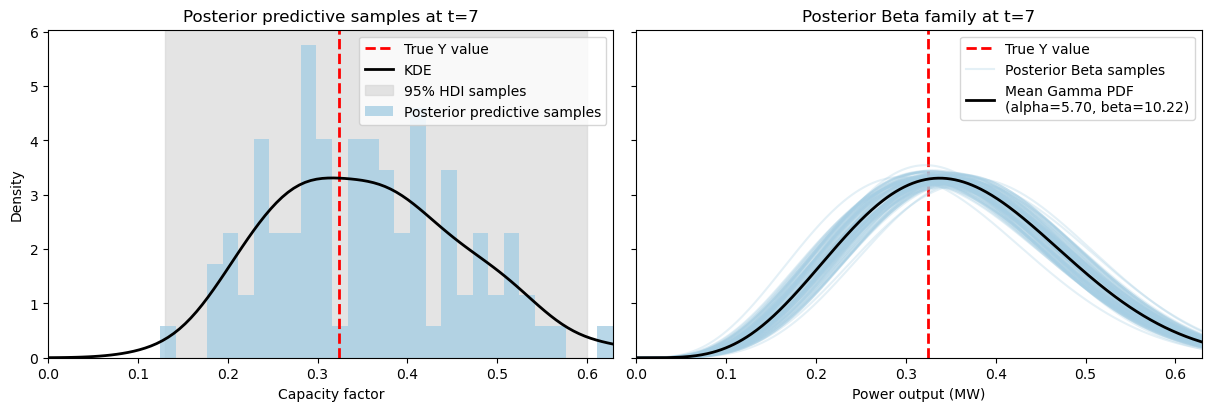

In [21]:
t = 7

# mu_t_samples = np.array(cf_mu[:,t])
# mu_t = np.mean(mu_t_samples)

hdi_lower, hdi_upper = hdi[t,0], hdi[t,1]


# choose common x-range (covers almost all mass, avoids long-tail zoom)
xmin = 0.0
xmax = float(np.quantile(y_samples, 0.995))  # or 0.999 if you prefer
if xmax <= xmin:
    xmax = float(y_samples.max()) * 1.1  # fallback

x = np.linspace(xmin, xmax, 400)

# Mean Gamma for reference
#mu_mean = float(np.mean(mu_t_samples))
beta_mean = dist.Beta(alpha_t, beta_t)
pdf_mean = np.array(jnp.exp(beta_mean.log_prob(jnp.array(x))))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True, sharex=True, sharey=True)

# Ensure identical limits and avoid autoscale surprises  
y_true = float(Y_test_cf[t])

for ax in axes:
    ax.set_xlim(xmin, xmax)
    ax.axvline(y_true, color='red', lw=2, linestyle='--', label='True Y value')
    # ax.axvline(mu_mean, color='orange', lw=2, linestyle='--', label='Mean mu')
    # ax.axvline(hdi_lower, color='gray', linestyle='--', lw=1.5, label='95% HDI')
    # ax.axvline(hdi_upper, color='gray', linestyle='--', lw=1.5)


# LEFT: posterior predictive histogram
# KDE vs histogram
kde = gaussian_kde(y_samples)
x_kde = np.linspace(xmin, xmax, 100)
axes[0].plot(x_kde, kde(x_kde), color='black', lw=2, label='KDE')
axes[0].axvspan(hdi_lower, hdi_upper, color="#D3D3D3", alpha=0.6, label='95% HDI samples')
axes[0].hist(
    y_samples,
    bins=30,
    density=True,
    alpha=0.8,
    color="#A6CEE3",  # soft blue for posterior samples
    label="Posterior predictive samples"
)
#axes[0].hist(y_samples, bins=25, range=(xmin, xmax), density=True, alpha=0.7, color='C0')
axes[0].set_title(f"Posterior predictive samples at t={t}")
axes[0].set_xlabel("Capacity factor")
axes[0].set_ylabel("Density")
axes[0].legend()

# RIGHT: bundle of Gammas
n_plot = min(200, len(alpha_t_samples))
for i in range(n_plot):
    a = float(alpha_t_samples[i])
    b = float(beta_t_samples[i])
    pdf = np.array(jnp.exp(dist.Beta(a,b).log_prob(jnp.array(x))))
     # Add label only to the first curve so legend isn’t cluttered
    if i == 0:
        axes[1].plot(x, pdf, color="#A6CEE3", alpha=0.3, label='Posterior Beta samples')
    else:
        axes[1].plot(x, pdf, color="#A6CEE3", alpha=0.3)

axes[1].plot(x, pdf_mean, color='black', lw=2, label=f"Mean Gamma PDF\n(alpha={alpha_t:.2f}, beta={beta_t:.2f})")
axes[1].set_title(f"Posterior Beta family at t={t}")
axes[1].set_xlabel("Power output (MW)")
axes[1].legend()



# Compute a common y-max across both panels and set it explicitly
ymax = max(axes[0].get_ylim()[1], axes[1].get_ylim()[1])
for ax in axes:
    ax.set_ylim(0, ymax)

plt.show()


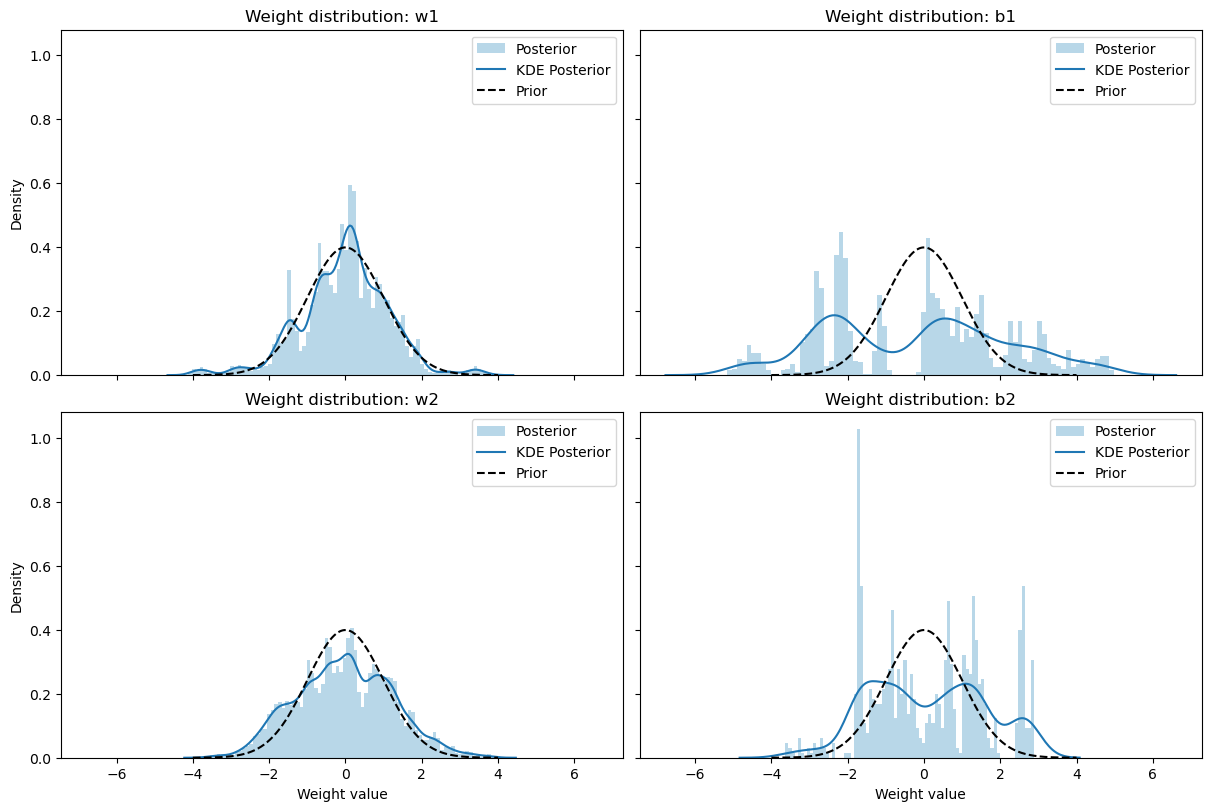

In [22]:
layers = [('w1', samples_beta['w1']), ('b1', samples_beta['b1']),
          ('w2', samples_beta['w2']), ('b2', samples_beta['b2'])]

fig, axes = plt.subplots(2, 2, figsize=(12,8),  constrained_layout=True, sharex=True, sharey=True) # shared x and y axes to make it better comparable
x = np.linspace(-4, 4, 400)
for ax, (name, arr) in zip(axes.ravel(), layers):
    post = arr.ravel()
    ax.hist(post, bins=80, density=True, alpha=0.8, color="#A6CEE3", label='Posterior') 
    sns.kdeplot(post, ax=ax, fill=False, color='#1f77b4', alpha=1, label='KDE Posterior')
    ax.plot(x, np.exp(dist.Normal(0.,1.).log_prob(x)), 'k--', lw=1.5, label='Prior')
    ax.set_title(f"Weight distribution: {name}"); ax.set_xlabel('Weight value'); ax.set_ylabel('Density')
    ax.legend()

#axes[-1, -1].legend(['Posterior KDE', 'Prior (N(0,1))', 'KDE Posterior'], fontsize=10) # one big legend

plt.show()


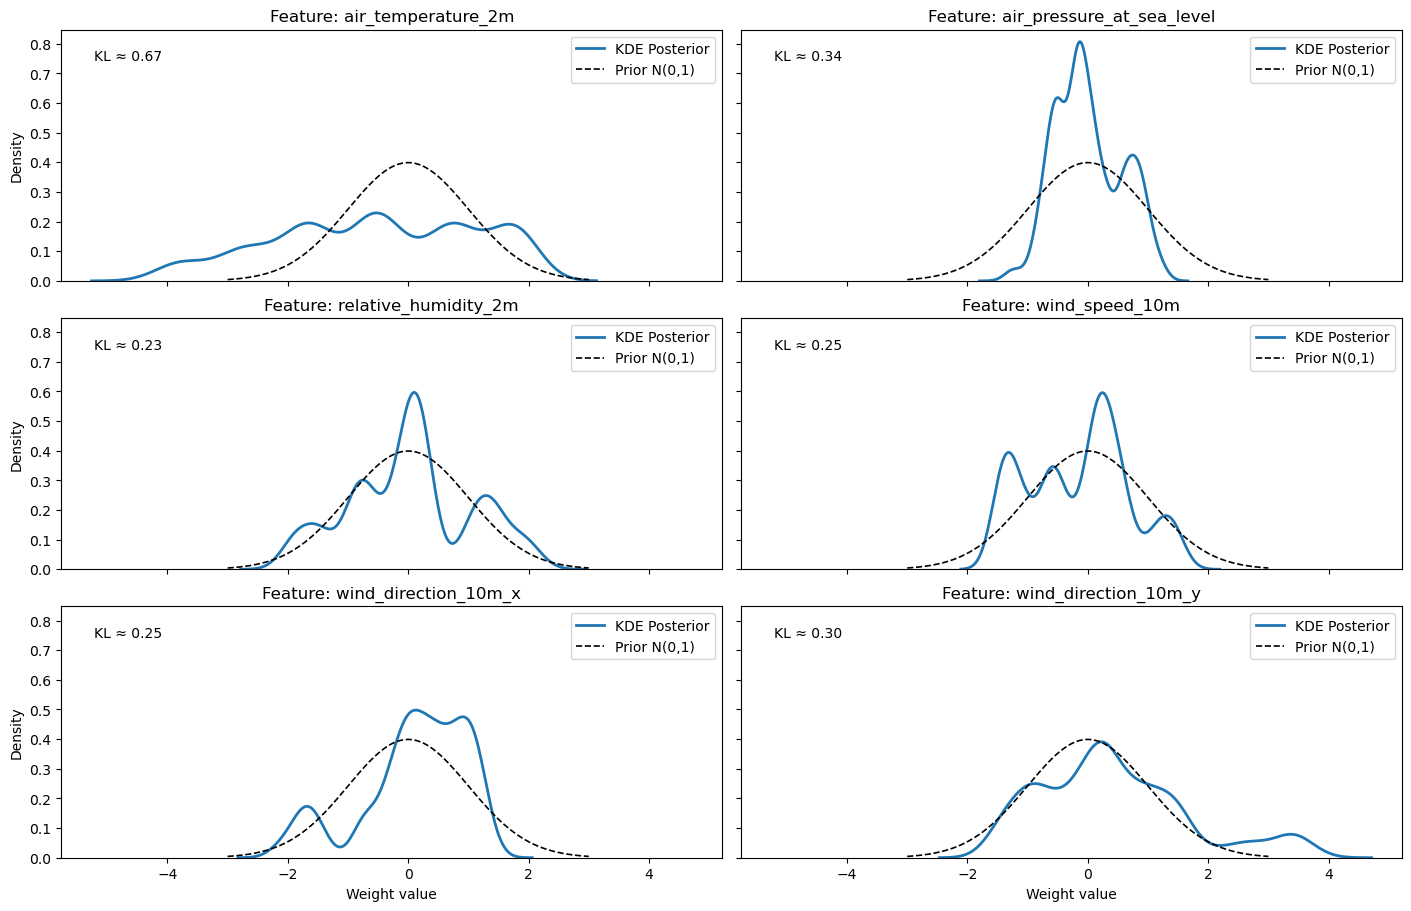

In [23]:
# Plot prior vs posterior of first weight layer for each feature
# Posterior samples
w1 = samples_beta['w1']  # shape [samples, features, 16]
F = w1.shape[1]
x = np.linspace(-3, 3, 400)

# Grid layout: 2 plots per row
ncols = 2
nrows = int(np.ceil(F / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(7 * ncols, 3 * nrows),
    constrained_layout=True,
    sharex=True,
    sharey=True
)
axes = axes.flatten()

for f, ax in enumerate(axes[:F]):
    post = w1[:, f, :].ravel()

    # Posterior KDE
    sns.kdeplot(post, ax=ax, color="#1f77b4", lw=2, label="KDE Posterior")

    # Prior
    ax.plot(x, np.exp(dist.Normal(0., 1.).log_prob(x)), color="black", ls="--", lw=1.2, label="Prior N(0,1)")

    # KL divergence estimate: D_KL(Posterior||Prior)
    kde = gaussian_kde(post)
    log_p_post = np.log(kde(post))
    log_p_prior = norm.logpdf(post, loc=0, scale=1)
    kl_est = np.mean(log_p_post - log_p_prior)

    ax.text(0.05, 0.92, f"KL ≈ {kl_est:.2f}", transform=ax.transAxes, fontsize=10, ha="left", va="top")
    ax.set_title(f"Feature: {feature_cols[f]}")
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Density")
    ax.legend()

# Hide any empty subplots
for ax in axes[F:]:
    ax.set_visible(False)

plt.show()


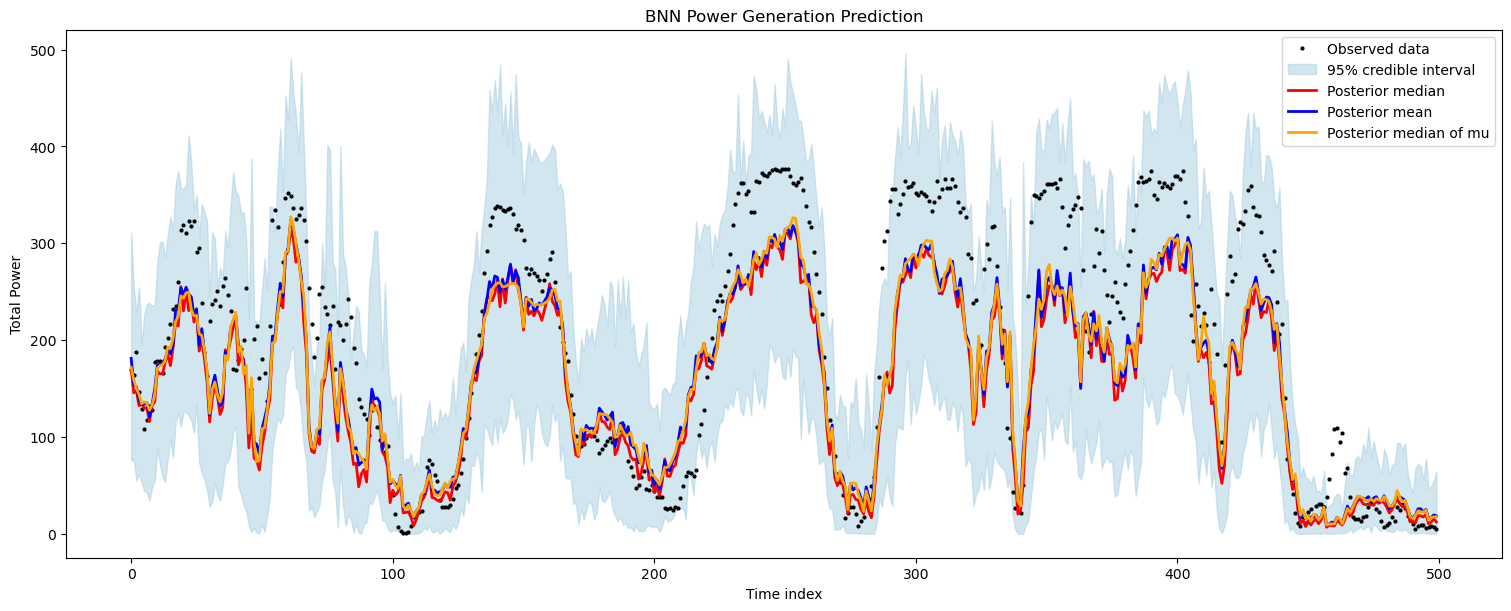

In [18]:
n_plot = 500
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)

ax.plot(Y_test_gen[:n_plot], ".", color="black", label="Observed data", markersize=4)
ax.fill_between(
    np.arange(n_plot),
    hdi[:n_plot, 0],
    hdi[:n_plot, 1],
    color="#A6CEE3", # alternative: "#lightgray"
    alpha=0.5,
    label="95% credible interval"
)

ax.plot(median[:n_plot], color="red", label="Posterior median", lw=2)
ax.plot(preds_mean[:n_plot], color="blue", label="Posterior mean", lw=2)
ax.plot(jax.numpy.median(mu[:,:n_plot], axis=0), "orange", lw=2, label="Posterior median of mu")

ax.set(
    xlabel="Time index",
    ylabel="Total Power",
    title="BNN Power Generation Prediction"
)

ax.legend()
plt.show()


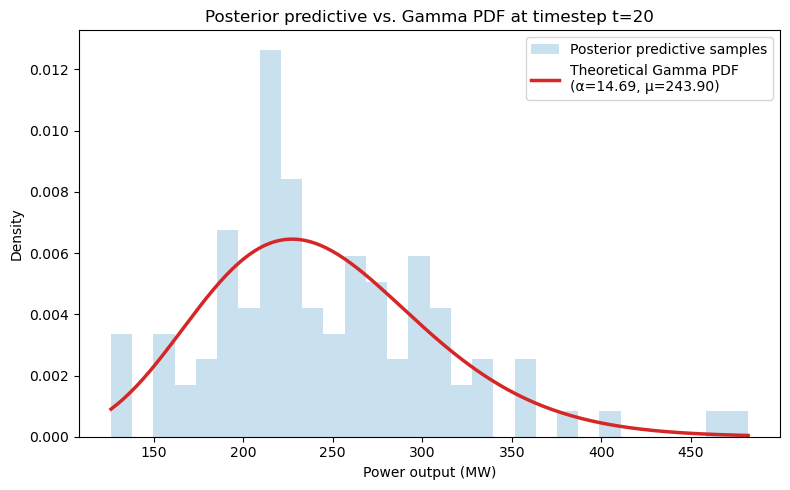

In [19]:
# pick a timestep
t = 20  # or any index you want to inspect

# posterior predictive samples
y_samples = np.array(preds[:, t])
mu_t_samples = np.array(mu[:, t])
alpha_t_samples = np.array(alpha[:, t])

# posterior mean parameters
mu_t = np.mean(mu_t_samples)
alpha_t = np.mean(alpha_t_samples)
rate_t = alpha_t / mu_t

# theoretical Gamma distribution
gamma_dist = dist.Gamma(concentration=alpha_t, rate=rate_t)
x = np.linspace(y_samples.min(), y_samples.max(), 200)
pdf = np.array(jnp.exp(gamma_dist.log_prob(jnp.array(x))))

# --- PLOT ---
plt.figure(figsize=(8, 5))
plt.hist(
    y_samples,
    bins=30,
    density=True,
    alpha=0.6,
    color="#A6CEE3",  # soft blue for posterior samples
    label="Posterior predictive samples"
)
plt.plot(
    x, pdf,
    color="#D62728",  # red for theoretical curve
    lw=2.5,
    label=f"Theoretical Gamma PDF\n(α={alpha_t:.2f}, μ={mu_t:.2f})"
)

plt.xlabel("Power output (MW)")
plt.ylabel("Density")
plt.title(f"Posterior predictive vs. Gamma PDF at timestep t={t}")
plt.legend()
plt.tight_layout()
plt.show()


Stacked HDI

In [21]:
hdi

array([[ 75.47592163, 311.20205688],
       [ 76.45365906, 253.59103394],
       [ 54.58733368, 228.94540405],
       ...,
       [  7.76824903, 261.60580444],
       [  0.42835364, 293.27575684],
       [  1.14407873, 349.9335022 ]], shape=(2161, 2))

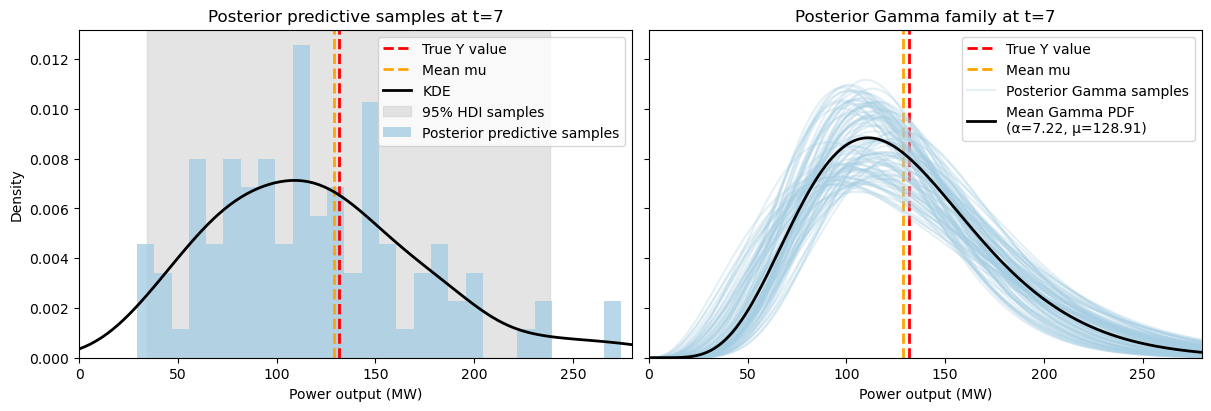

In [20]:
t = 7

y_samples = np.asarray(preds[:, t])
mu_t_samples = np.asarray(mu[:, t])
alpha_t_samples = np.asarray(alpha[:, t])

hdi_lower, hdi_upper = hdi[t,0], hdi[t,1]


# choose common x-range (covers almost all mass, avoids long-tail zoom)
xmin = 0.0
xmax = float(np.quantile(y_samples, 0.995))  # or 0.999 if you prefer
if xmax <= xmin:
    xmax = float(y_samples.max()) * 1.1  # fallback

x = np.linspace(xmin, xmax, 400)

# Mean Gamma for reference
alpha_mean = float(np.mean(alpha_t_samples))
mu_mean = float(np.mean(mu_t_samples))
rate_mean = alpha_mean / mu_mean
gamma_mean = dist.Gamma(concentration=alpha_mean, rate=rate_mean)
pdf_mean = np.array(jnp.exp(gamma_mean.log_prob(jnp.array(x))))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True, sharex=True, sharey=True)

# Ensure identical limits and avoid autoscale surprises  
y_true = float(Y_test_gen[t])

for ax in axes:
    ax.set_xlim(xmin, xmax)
    ax.axvline(y_true, color='red', lw=2, linestyle='--', label='True Y value')
    ax.axvline(mu_mean, color='orange', lw=2, linestyle='--', label='Mean mu')
    # ax.axvline(hdi_lower, color='gray', linestyle='--', lw=1.5, label='95% HDI')
    # ax.axvline(hdi_upper, color='gray', linestyle='--', lw=1.5)


# LEFT: posterior predictive histogram
# KDE vs histogram
kde = gaussian_kde(y_samples)
x_kde = np.linspace(xmin, xmax, 100)
axes[0].plot(x_kde, kde(x_kde), color='black', lw=2, label='KDE')
axes[0].axvspan(hdi_lower, hdi_upper, color="#D3D3D3", alpha=0.6, label='95% HDI samples')
axes[0].hist(
    y_samples,
    bins=30,
    density=True,
    alpha=0.8,
    color="#A6CEE3",  # soft blue for posterior samples
    label="Posterior predictive samples"
)
#axes[0].hist(y_samples, bins=25, range=(xmin, xmax), density=True, alpha=0.7, color='C0')
axes[0].set_title(f"Posterior predictive samples at t={t}")
axes[0].set_xlabel("Power output (MW)")
axes[0].set_ylabel("Density")
axes[0].legend()

# RIGHT: bundle of Gammas
n_plot = min(200, len(alpha_t_samples))
for i in range(n_plot):
    a = float(alpha_t_samples[i])
    m = float(mu_t_samples[i])
    r = a / m
    pdf = np.array(jnp.exp(dist.Gamma(concentration=a, rate=r).log_prob(jnp.array(x))))
     # Add label only to the first curve so legend isn’t cluttered
    if i == 0:
        axes[1].plot(x, pdf, color="#A6CEE3", alpha=0.3, label='Posterior Gamma samples')
    else:
        axes[1].plot(x, pdf, color="#A6CEE3", alpha=0.3)

axes[1].plot(x, pdf_mean, color='black', lw=2, label=f"Mean Gamma PDF\n(α={alpha_mean:.2f}, μ={mu_mean:.2f})")
axes[1].set_title(f"Posterior Gamma family at t={t}")
axes[1].set_xlabel("Power output (MW)")
axes[1].legend()



# Compute a common y-max across both panels and set it explicitly
ymax = max(axes[0].get_ylim()[1], axes[1].get_ylim()[1])
for ax in axes:
    ax.set_ylim(0, ymax)

plt.show()


In [58]:
samples_gamma['w1'].shape

(100, 6, 16)

In [43]:
preds.shape

(100, 2161)

In [21]:
# Kolmogorov Smirnov test for one time step
# H_0: samples follow a gamma distribution
t=61
y_test_preds = np.asarray(preds[:, t])
from scipy.stats import gamma, kstest

k_hat, loc_hat, theta_hat = gamma.fit(y_test_preds, floc=0)
cdf_hat = lambda x: gamma.cdf(x, k_hat, loc=0, scale=theta_hat)
stat, pval = kstest(y_test_preds, cdf_hat)

print(stat, pval)


0.07654447744364512 0.5745932211210365


KS statistic = 0.0765, p-value = 0.5746


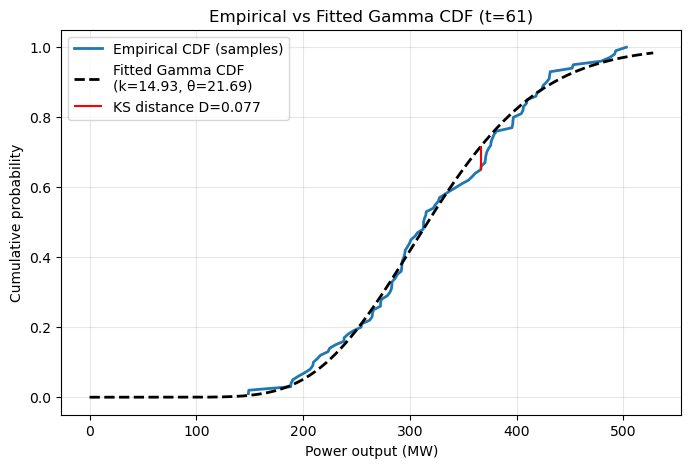

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma, kstest

# Posterior predictive samples for one timestep
y = np.asarray(preds[:, t]) 

k_hat, loc_hat, theta_hat = gamma.fit(y, floc=0)

# KS statistic and p-value
cdf_hat = lambda x: gamma.cdf(x, k_hat, loc=0, scale=theta_hat)
stat, pval = kstest(y, cdf_hat)
print(f"KS statistic = {stat:.4f}, p-value = {pval:.4f}")

# Theoretical CDF
x = np.linspace(0, np.max(y)*1.05, 400)
cdf_theoretical = gamma.cdf(x, k_hat, loc=0, scale=theta_hat)

# Empirical CDF of your samples
y_sorted = np.sort(y)
cdf_empirical = np.arange(1, len(y_sorted)+1) / len(y_sorted)


plt.figure(figsize=(8,5))
plt.plot(y_sorted, cdf_empirical, color='C0', lw=2, label='Empirical CDF (samples)')
plt.plot(x, cdf_theoretical, color='black', lw=2, ls='--',
         label=f'Fitted Gamma CDF\n(k={k_hat:.2f}, θ={theta_hat:.2f})')

# Show maximum KS deviation D
idx_max = np.argmax(np.abs(cdf_empirical - cdf_hat(y_sorted)))
plt.vlines(y_sorted[idx_max],
           cdf_empirical[idx_max], cdf_hat(y_sorted[idx_max]),
           color='red', lw=1.5, label=f"KS distance D={stat:.3f}")

plt.title(f"Empirical vs Fitted Gamma CDF (t={t})")
plt.xlabel("Power output (MW)")
plt.ylabel("Cumulative probability")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


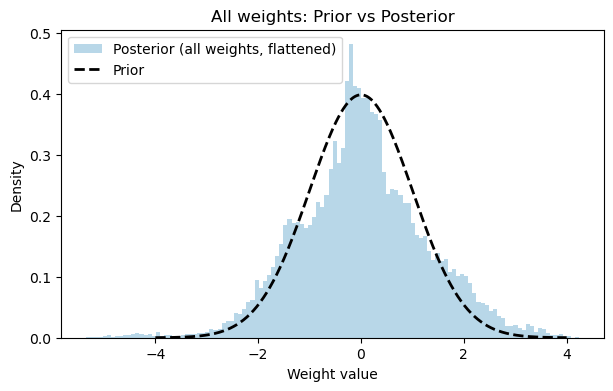

In [24]:
def flatten(*arrays):
    return np.concatenate([a.ravel() for a in arrays], axis=0)

# Posterior-Samples (dict aus MCMC): samples['w1'], samples['b1'], ...
w_flat = flatten(samples_gamma['w1'], samples_gamma['b1'], samples_gamma['w2'], samples_gamma['b2'])
prior = dist.Normal(0., 1.)
x = np.linspace(-4, 4, 500)

plt.figure(figsize=(7,4))
plt.hist(w_flat, bins=120, density=True, alpha=0.8, color="#A6CEE3", label='Posterior (all weights, flattened)')
plt.plot(x, np.exp(prior.log_prob(x)), 'k--', lw=2, label='Prior')
plt.xlabel('Weight value'); plt.ylabel('Density'); plt.legend(); plt.title('All weights: Prior vs Posterior'); plt.show()


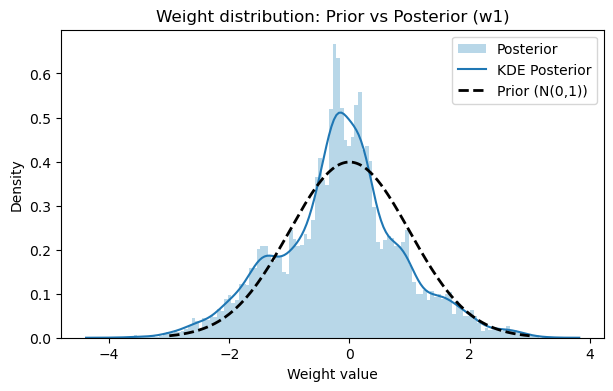

In [25]:
# Posterior samples (z. B. aus MCMC)
w1_post = np.ravel(samples_gamma['w1'])
#w1_post = samples_gamma['w1'][:,0,0]
prior = dist.Normal(0, 1)

# Plot
plt.figure(figsize=(7,4))
plt.hist(w1_post, bins=120, density=True, alpha=0.8, color="#A6CEE3", label='Posterior')
x = np.linspace(-3, 3, 200)
sns.kdeplot(w1_post, label='KDE Posterior', fill=False, color='#1f77b4', alpha=1)
plt.plot(x, np.exp(prior.log_prob(x)), 'k--', lw=2, label='Prior (N(0,1))')
plt.title("Weight distribution: Prior vs Posterior (w1)")
plt.xlabel("Weight value")
plt.ylabel("Density")
plt.legend()
plt.show()


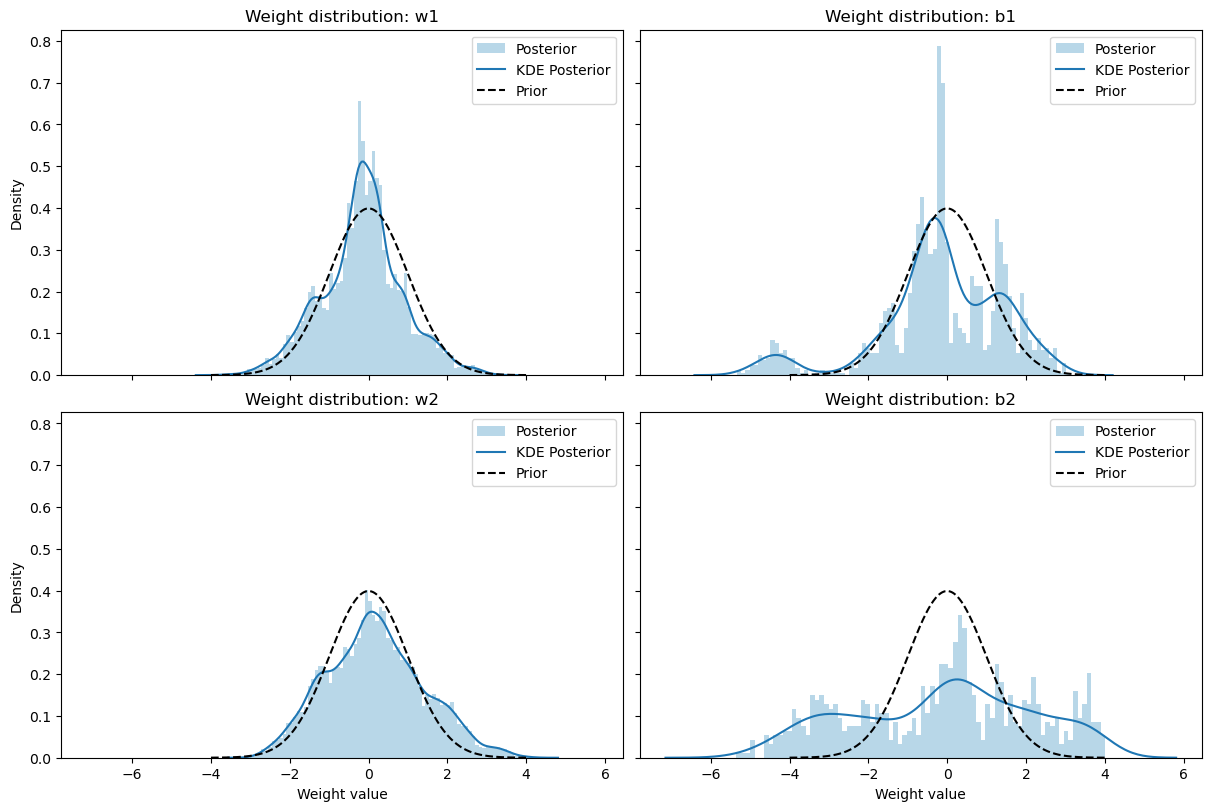

In [26]:
layers = [('w1', samples_gamma['w1']), ('b1', samples_gamma['b1']),
          ('w2', samples_gamma['w2']), ('b2', samples_gamma['b2'])]

fig, axes = plt.subplots(2, 2, figsize=(12,8),  constrained_layout=True, sharex=True, sharey=True) # shared x and y axes to make it better comparable
x = np.linspace(-4, 4, 400)
for ax, (name, arr) in zip(axes.ravel(), layers):
    post = arr.ravel()
    ax.hist(post, bins=80, density=True, alpha=0.8, color="#A6CEE3", label='Posterior') 
    sns.kdeplot(post, ax=ax, fill=False, color='#1f77b4', alpha=1, label='KDE Posterior')
    ax.plot(x, np.exp(dist.Normal(0.,1.).log_prob(x)), 'k--', lw=1.5, label='Prior')
    ax.set_title(f"Weight distribution: {name}"); ax.set_xlabel('Weight value'); ax.set_ylabel('Density')
    ax.legend()

#axes[-1, -1].legend(['Posterior KDE', 'Prior (N(0,1))', 'KDE Posterior'], fontsize=10) # one big legend

plt.show()


In [134]:
samples_gamma['w1'].shape

(100, 6, 16)

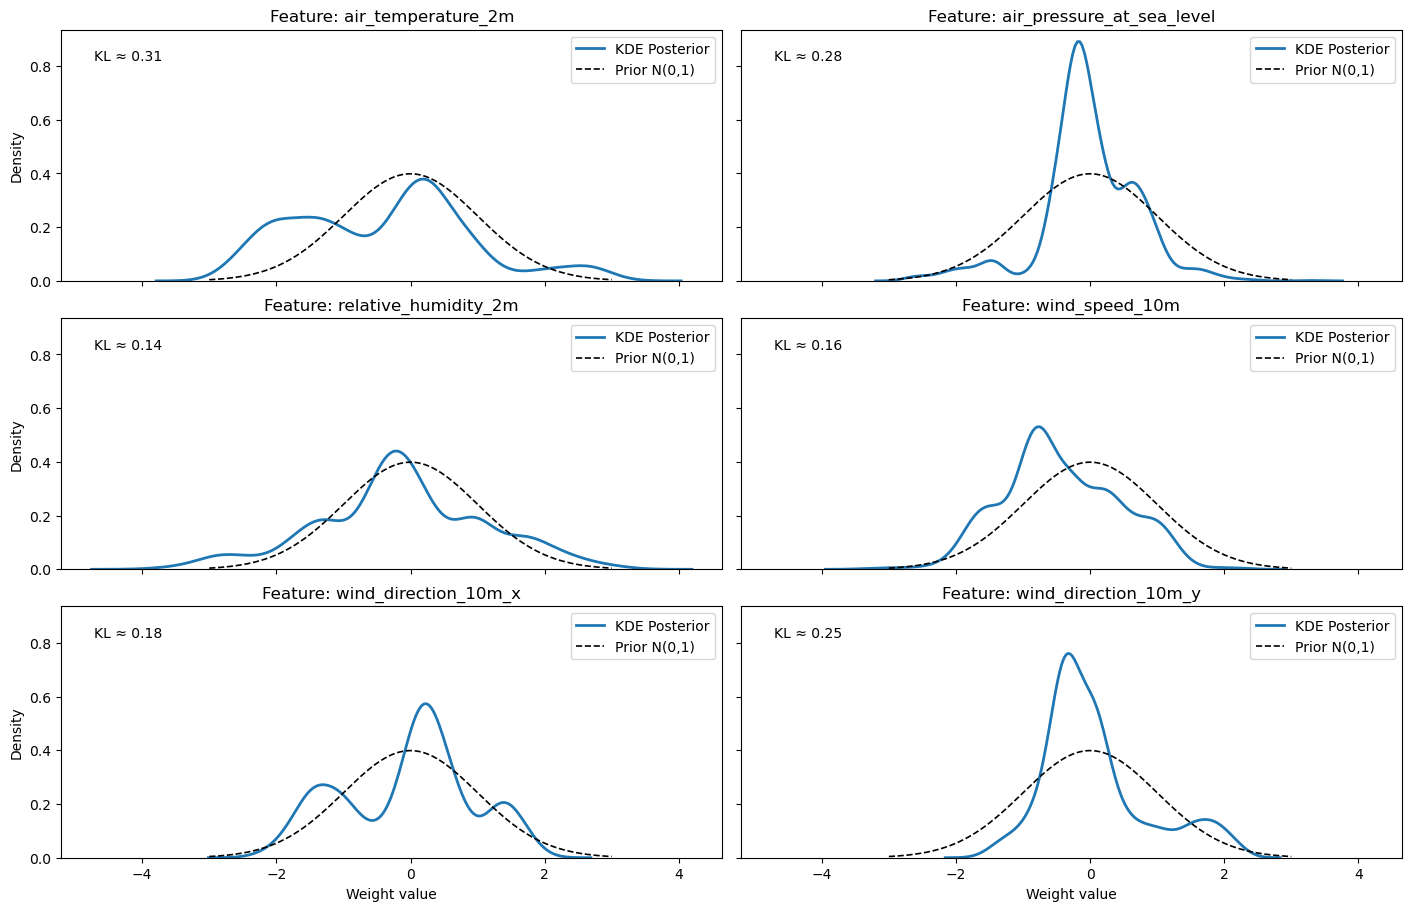

In [ ]:
# Plot prior vs posterior of first weight layer for each feature
# Posterior samples
w1 = samples_gamma['w1']  # shape [samples, features, 16]
F = w1.shape[1]
x = np.linspace(-3, 3, 400)

# Grid layout: 2 plots per row
ncols = 2
nrows = int(np.ceil(F / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(7 * ncols, 3 * nrows),
    constrained_layout=True,
    sharex=True,
    sharey=True
)
axes = axes.flatten()

for f, ax in enumerate(axes[:F]):
    post = w1[:, f, :].ravel()

    # Posterior KDE
    sns.kdeplot(post, ax=ax, color="#1f77b4", lw=2, label="KDE Posterior")

    # Prior
    ax.plot(x, np.exp(dist.Normal(0., 1.).log_prob(x)), color="black", ls="--", lw=1.2, label="Prior N(0,1)")

    # KL divergence estimate: D_KL(Posterior||Prior)
    kde = gaussian_kde(post)
    log_p_post = np.log(kde(post))
    log_p_prior = norm.logpdf(post, loc=0, scale=1)
    kl_est = np.mean(log_p_post - log_p_prior)

    ax.text(0.05, 0.92, f"KL ≈ {kl_est:.2f}", transform=ax.transAxes, fontsize=10, ha="left", va="top")
    ax.set_title(f"Feature: {feature_cols[f]}")
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Density")
    ax.legend()

# Hide any empty subplots
for ax in axes[F:]:
    ax.set_visible(False)

plt.show()


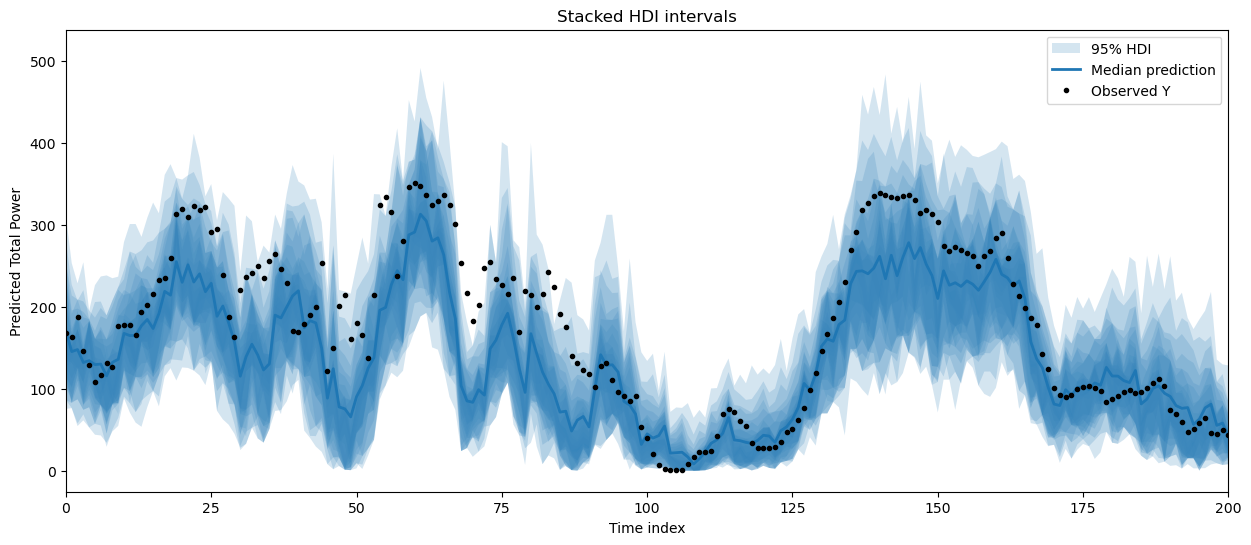

In [28]:
# Only plot first n_plot timesteps
# TODO ohne linien, percentile verwenden, beides
n_plot = 1000

# Compute multiple HDI levels
hdi_probs = np.arange(0.05, 1.0, 0.05)
preds_hdi = np.expand_dims(preds, axis=0)
hdis = {float(p): az.hdi(preds_hdi, hdi_prob=float(p)) for p in hdi_probs}

X_new = np.arange(n_plot)
median = np.percentile(preds, 50, axis=0)

plt.figure(figsize=(15, 6))
max_p = max(hdis.keys())
for p in hdi_probs:
    hdi = hdis[p][:n_plot]
    alpha = 0.2 * float(p)
    label = f'{int(p*100)}% HDI' if p == max_p else None
    plt.fill_between(X_new, hdi[:, 0], hdi[:, 1], color='C0', alpha=alpha, label=label, lw=0)

plt.plot(X_new, median[:n_plot], color='C0', lw=2, label='Median prediction')
plt.plot(Y_test_gen[:n_plot], ".", color="black", label="Observed Y")
plt.xlim(0,200)
plt.title("Stacked HDI intervals")
plt.xlabel("Time index")
plt.ylabel("Predicted Total Power")
plt.legend()
plt.show()


Std noise of model samples

PIT (Probability Integral Transform)
- Checks calibration of probabilistic forecasts
- Model well-calibrated -> values uniformly distributed
- For each observation $y_i$:
    - Take all model’s predictive samples for that data point
    - Compute how many of those samples are less than or equal to the actual observed value
    - PIT value $u_i = P_{\hat{Y_i}}​​(Y\leq y)$
    - with MCMC: $u_i \approx \frac{1}{S} \sum_{s=1}^S 1[y_i^{(s)}\leq y_i]$

PIT mean: 0.5884914391485423 (should be uniform if calibrated)


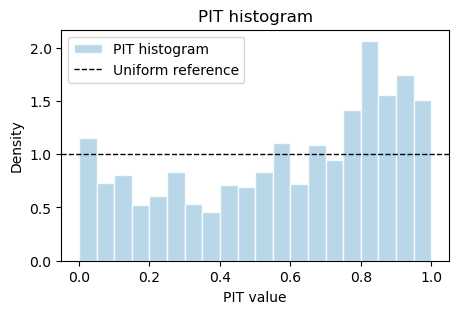

In [29]:
pits = np.array([percentileofscore(preds[:, t], Y_test_gen[t], kind='mean') / 100.0 for t in range(preds.shape[1])])
pits_mean = pits.mean()
print(f"PIT mean: {pits_mean} (should be uniform if calibrated)")

plt.figure(figsize=(5,3))
plt.hist(pits, bins=20, range=(0,1), density=True, alpha=0.8, color="#A6CEE3", edgecolor="white", label="PIT histogram")
plt.axhline(1.0, color='k', ls='--', lw=1, label="Uniform reference")
plt.xlabel("PIT value")
plt.ylabel("Density")
plt.title("PIT histogram")
plt.legend()
plt.show()

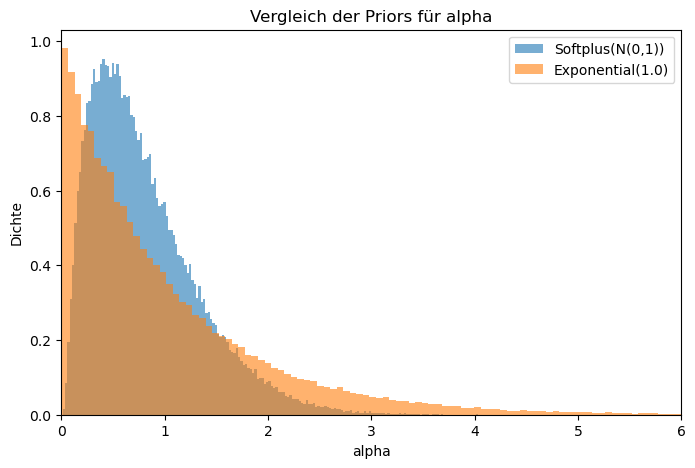

In [30]:
num_samples = 100000
rng_key = jax.random.key(0)

alpha_normal = dist.Normal(0, 1.0).sample(rng_key, (num_samples,))
alpha_normal = jax.nn.softplus(alpha_normal) + 1e-6
alpha_expon = dist.Exponential(1.0).sample(rng_key, (num_samples,))

plt.figure(figsize=(8, 5))
plt.hist(alpha_normal, bins=200, density=True, alpha=0.6, label="Softplus(N(0,1))")
plt.hist(alpha_expon, bins=200, density=True, alpha=0.6, label="Exponential(1.0)")

plt.xlim(0, 6)
plt.xlabel("alpha")
plt.ylabel("Dichte")
plt.title("Vergleich der Priors für alpha")
plt.legend()
plt.show()


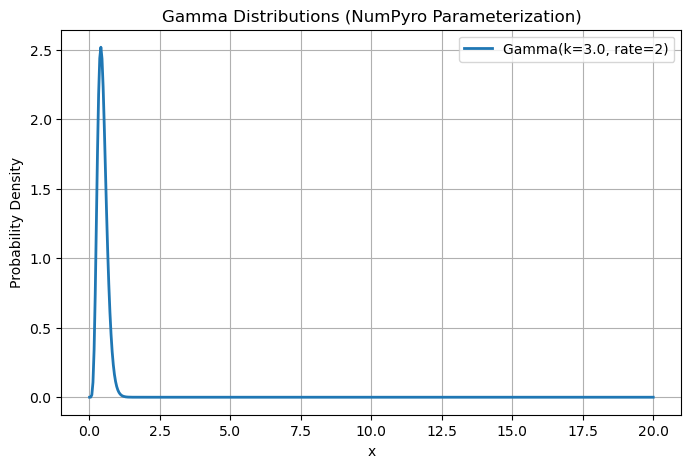

In [31]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
from numpyro.distributions import Gamma

# x-axis: positive support
x = jnp.linspace(0.01, 20, 500)

# Define two Gamma distributions with different parameters
# Gamma(concentration=k, rate=θ)
dist1 = Gamma(7.822808616205009, 16.687328)   # mean = 4.0
dist2 = Gamma(concentration=20.0, rate=2)   # mean = 7.0

# Compute PDF values
pdf1 = jnp.exp(dist1.log_prob(x))
pdf2 = jnp.exp(dist2.log_prob(x))

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x, pdf1, label=f"Gamma(k=3.0, rate=2)", linewidth=2)
#plt.plot(x, pdf2, label=f"Gamma(k=20.0, rate=2)", linewidth=2)
plt.title("Gamma Distributions (NumPyro Parameterization)")
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(True)
plt.show()
